    Step 1: Data Understanding & Preprocessing
    •	Load and explore the dataset.
    •	Check for missing values and handle them.
    •	Convert categorical variables (Fuel_Type, Mileage, Airbags) into numerical format.


In [37]:
import warnings
warnings.filterwarnings('ignore')

In [38]:
import pandas as pd
import numpy as np
path=r"https://raw.githubusercontent.com/rushidhende06-pixel/Datasets/refs/heads/main/car_price_prediction.csv"
df=pd.read_csv(path)
df.head()


,ID,Price,Levy,Manufacturer,Model,Prod. year,Category,Leather interior,Fuel type,Engine volume,Mileage,Cylinders,Gear box type,Drive wheels,Doors,Wheel,Color,Airbags
0,45654403,13328,1399,LEXUS,RX 450,2010,Jeep,Yes,Hybrid,3.5,186005 km,6.0,Automatic,4x4,04-May,Left wheel,Silver,12
1,44731507,16621,1018,CHEVROLET,Equinox,2011,Jeep,No,Petrol,3,192000 km,6.0,Tiptronic,4x4,04-May,Left wheel,Black,8
2,45774419,8467,-,HONDA,FIT,2006,Hatchback,No,Petrol,1.3,200000 km,4.0,Variator,Front,04-May,Right-hand drive,Black,2
3,45769185,3607,862,FORD,Escape,2011,Jeep,Yes,Hybrid,2.5,168966 km,4.0,Automatic,4x4,04-May,Left wheel,White,0
4,45809263,11726,446,HONDA,FIT,2014,Hatchback,Yes,Petrol,1.3,91901 km,4.0,Automatic,Front,04-May,Left wheel,Silver,4


In [39]:
df.shape

(19237, 18)

In [40]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 19237 entries, 0 to 19236
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ID                19237 non-null  int64  
 1   Price             19237 non-null  int64  
 2   Levy              19237 non-null  str    
 3   Manufacturer      19237 non-null  str    
 4   Model             19237 non-null  str    
 5   Prod. year        19237 non-null  int64  
 6   Category          19237 non-null  str    
 7   Leather interior  19237 non-null  str    
 8   Fuel type         19237 non-null  str    
 9   Engine volume     19237 non-null  str    
 10  Mileage           19237 non-null  str    
 11  Cylinders         19237 non-null  float64
 12  Gear box type     19237 non-null  str    
 13  Drive wheels      19237 non-null  str    
 14  Doors             19237 non-null  str    
 15  Wheel             19237 non-null  str    
 16  Color             19237 non-null  str    
 17  Airb

In [41]:
df.isna().sum()

ID                  0
Price               0
Levy                0
Manufacturer        0
Model               0
Prod. year          0
Category            0
Leather interior    0
Fuel type           0
Engine volume       0
Mileage             0
Cylinders           0
Gear box type       0
Drive wheels        0
Doors               0
Wheel               0
Color               0
Airbags             0
dtype: int64

In [42]:
df.dtypes

ID                    int64
Price                 int64
Levy                    str
Manufacturer            str
Model                   str
Prod. year            int64
Category                str
Leather interior        str
Fuel type               str
Engine volume           str
Mileage                 str
Cylinders           float64
Gear box type           str
Drive wheels            str
Doors                   str
Wheel                   str
Color                   str
Airbags               int64
dtype: object

In [43]:
# Remove 'km' and convert Mileage to numeric
df["Mileage"] = (
    df["Mileage"]
    .astype(str)
    .str.replace(" km", "", regex=False)
    .astype(float)
)

print(df["Mileage"].head())
print("\nMileage Data Type:", df["Mileage"].dtype)

0    186005.0
1    192000.0
2    200000.0
3    168966.0
4     91901.0
Name: Mileage, dtype: float64

Mileage Data Type: float64


In [44]:
from sklearn.preprocessing import LabelEncoder

# Create LabelEncoder
le = LabelEncoder()

# Convert Fuel type into numerical format
df["Fuel type"] = le.fit_transform(df["Fuel type"].astype(str))

# Display the result
print(df["Fuel type"].head())

# Display category mapping
print("\nFuel Type Mapping:")
for category, number in zip(le.classes_, le.transform(le.classes_)):
    print(category, ":", number)

0    2
1    5
2    5
3    2
4    5
Name: Fuel type, dtype: int64

Fuel Type Mapping:
CNG : 0
Diesel : 1
Hybrid : 2
Hydrogen : 3
LPG : 4
Petrol : 5
Plug-in Hybrid : 6


In [45]:
print(df["Fuel type"].value_counts())

Fuel type
5    10150
1     4036
2     3578
4      892
0      494
6       86
3        1
Name: count, dtype: int64


In [46]:
# Convert Airbags to numeric format
df["Airbags"] = pd.to_numeric(df["Airbags"], errors="coerce")

# Display the result
print(df["Airbags"].head())

# Check data type
print("\nAirbags Data Type:", df["Airbags"].dtype)

0    12
1     8
2     2
3     0
4     4
Name: Airbags, dtype: int64

Airbags Data Type: int64


In [47]:
# Levy: "-"  missing -> NaN, mag number
df["Levy"] = pd.to_numeric(df["Levy"].replace("-", np.nan))


df["Engine"] = df["Engine volume"].str.extract(r"(\d+\.?\d*)").astype(float)
df["Turbo"] = df["Engine volume"].str.contains("Turbo").astype(int)

df["Age"] = 2020 - df["Prod. year"]

df[["Levy", "Engine", "Turbo", "Age", "Mileage", "Airbags"]].head()

,Levy,Engine,Turbo,Age,Mileage,Airbags
0,1399.0,3.5,0,10,186005.0,12
1,1018.0,3.0,0,9,192000.0,8
2,NaN,1.3,0,14,200000.0,2
3,862.0,2.5,0,9,168966.0,0
4,446.0,1.3,0,6,91901.0,4


In [48]:
df = df.drop_duplicates()

In [49]:
upper_price = df["Price"].quantile(0.995)
df = df[
    (df["Price"] >= 500) & (df["Price"] <= upper_price) &
    (df["Mileage"] > 0) & (df["Mileage"] < 1_000_000)
].copy()

print("Rows after cleaning:", df.shape[0])
print("\nMissing values after cleaning:")
print(df.isna().sum()[df.isna().sum() > 0])

Rows after cleaning: 16539

Missing values after cleaning:
Levy    4916
dtype: int64


    Step 2: Exploratory Data Analysis (EDA)
    •	Generate descriptive statistics.
    •	Create visualizations (histograms, scatter plots, boxplots, correlation heatmap).
    •	Identify relationships between independent variables and selling price


In [50]:
df.describe()

,ID,Price,Levy,Prod. year,Fuel type,Mileage,Cylinders,Airbags,Engine,Turbo,Age
count,1.653900e+04,16539.000000,11623.000000,16539.000000,16539.000000,16539.000000,16539.000000,16539.000000,16539.000000,16539.000000,16539.000000
mean,4.560798e+07,18355.107201,893.795664,2011.027692,3.435637,144059.212407,4.537880,6.496342,2.277913,0.104057,8.972308
std,7.338637e+05,15595.359763,455.428668,5.405290,1.813206,100348.241682,1.166277,4.174673,0.849530,0.305344,5.405290
min,2.436776e+07,500.000000,87.000000,1953.000000,0.000000,13.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,4.571960e+07,7840.000000,640.000000,2009.000000,2.000000,76000.000000,4.000000,4.000000,1.800000,0.000000,5.000000
50%,4.577419e+07,14740.000000,781.000000,2012.000000,5.000000,128147.000000,4.000000,4.000000,2.000000,0.000000,8.000000
75%,4.580213e+07,23521.000000,1053.000000,2015.000000,5.000000,187500.000000,4.000000,12.000000,2.500000,0.000000,11.000000
max,4.581665e+07,103491.000000,11714.000000,2020.000000,6.000000,999999.000000,16.000000,16.000000,20.000000,1.000000,67.000000


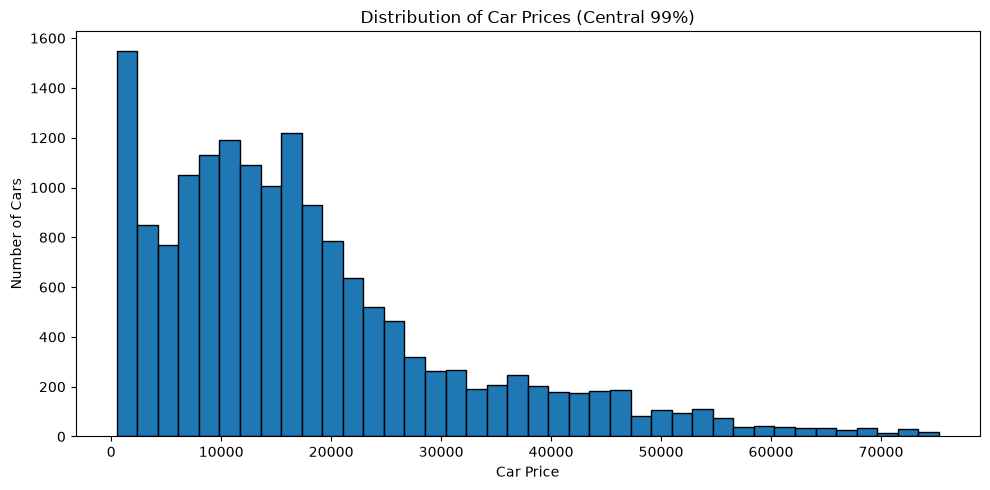

In [51]:
import matplotlib.pyplot as plt

# Keep positive prices for plotting
prices = df.loc[df["Price"] > 0, "Price"]

# Use the 99th percentile as the viewing limit
upper_limit = prices.quantile(0.99)
prices_to_plot = prices[prices <= upper_limit]

plt.figure(figsize=(10, 5))
plt.hist(prices_to_plot, bins=40, edgecolor="black")

plt.xlabel("Car Price")
plt.ylabel("Number of Cars")
plt.title("Distribution of Car Prices (Central 99%)")
plt.tight_layout()
plt.show()

 The car price distribution contains extreme values that require further investigation. These values should not be removed from the dataset without checking whether they are genuine or incorrect records.  


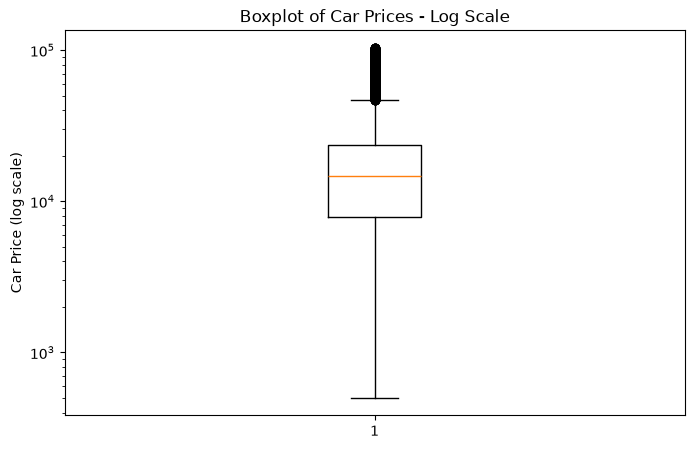

In [52]:

plt.figure(figsize=(8, 5))

plt.boxplot(df["Price"])

plt.yscale("log")
plt.ylabel("Car Price (log scale)")
plt.title("Boxplot of Car Prices - Log Scale")

plt.show()

observation:The boxplot helps visualize the spread and median of car prices.

Points beyond the whiskers indicate potential outliers.

Extremely high prices can make the central box appear compressed.

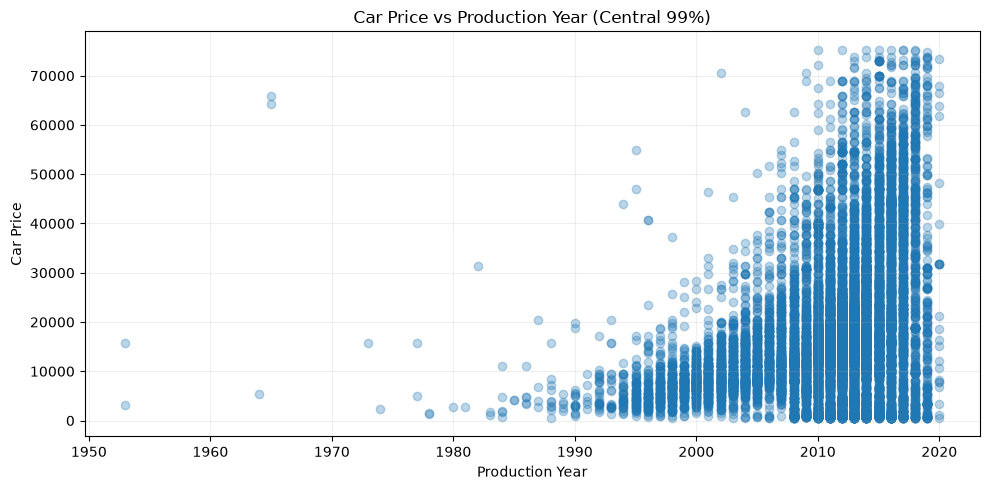

In [53]:

import matplotlib.pyplot as plt

# Limit prices for visualization only
upper_limit = df["Price"].quantile(0.99)
plot_df = df[df["Price"] <= upper_limit]

plt.figure(figsize=(10, 5))

plt.scatter(
    plot_df["Prod. year"],
    plot_df["Price"],
    alpha=0.3
)

plt.xlabel("Production Year")
plt.ylabel("Car Price")
plt.title("Car Price vs Production Year (Central 99%)")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


**Observation:** The graph indicates a positive relationship between production year and car price. In general, newer cars tend to have higher prices. However, prices vary among cars from the same production year, so other features are also important for price prediction.

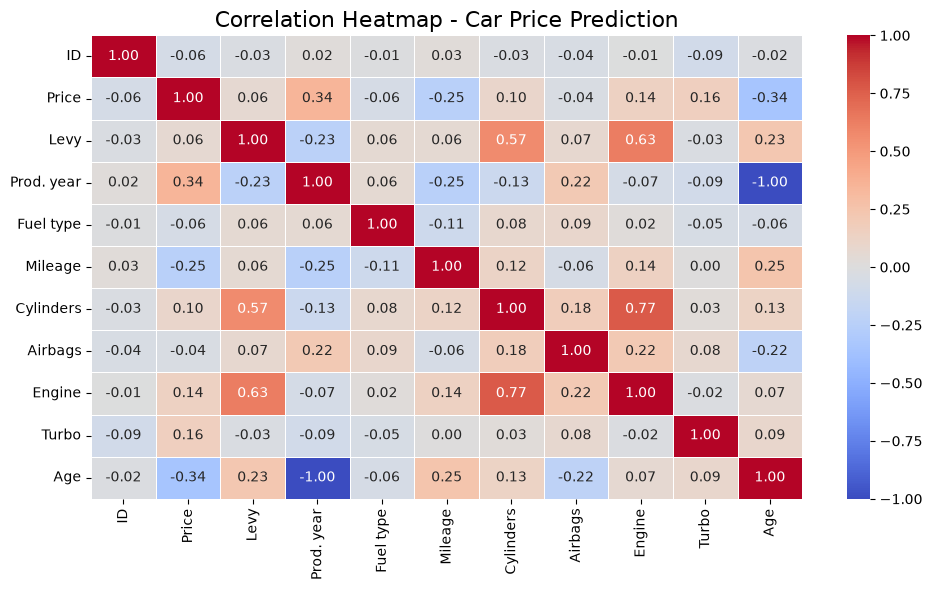

In [54]:

import matplotlib.pyplot as plt
import seaborn as sns

# Select numerical columns
numeric_df = df.select_dtypes(include="number")

# Calculate correlations
correlation = numeric_df.corr()

# Draw heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap - Car Price Prediction", fontsize=16)
plt.tight_layout()
plt.show()


In [55]:
price_correlation = numeric_df.corr()["Price"].sort_values(ascending=False)
print("Correlation of Variables with Car Price:")
display(price_correlation)

Correlation of Variables with Car Price:


Price         1.000000
Prod. year    0.344672
Turbo         0.162260
Engine        0.143866
Cylinders     0.096854
Levy          0.063036
Airbags      -0.037786
Fuel type    -0.061729
ID           -0.064995
Mileage      -0.247961
Age          -0.344672
Name: Price, dtype: float64

In [56]:
# Fill missing Levy values with the median
df["Levy"] = df["Levy"].fillna(df["Levy"].median())

# Check missing values
print(df["Levy"].isnull().sum())

0


Outlier Handling 


In [57]:
cat = list(df.select_dtypes(include='object').columns) 
con = list(df.select_dtypes(include='number').columns)

In [58]:
import numpy as np
out_summary = {}
for col in con:

    q1 = np.percentile(df[col], 25)
    q3 = np.percentile(df[col], 75)

    iqr = q3 - q1 

    minimun = q1 - 1.5 * iqr
    maximum = q3 + 1.5 * iqr

    lower_out = df[col] < minimun
    upper_out = df[col] > maximum

    outliers = df[lower_out | upper_out]

    print("=================")
    print(f"Outliers less than minimum: {df[lower_out]}")
    print(f"Outliers more than maximum: {df[upper_out]}")
    print(f"number of outliers for {col}: {len(outliers)}")
    out_summary[col] = {
        "lower": minimun,
        "upper": maximum,
        "outlier_count": len(outliers),
        "outlier_pct": round(len(outliers)/len(df) * 100, 2)
    }

out_report = pd.DataFrame(out_summary).T
out_report

Outliers less than minimum:              ID  Price    Levy   Manufacturer           Model  Prod. year  \
1      44731507  16621  1018.0      CHEVROLET         Equinox        2011   
15     45465200    549  1079.0         TOYOTA             CHR        2018   
21     45168471  20698   586.0         TOYOTA           Prius        2012   
30     44944581  15681  1288.0  MERCEDES-BENZ            Vito        2007   
34     45542380  24462   781.0           JEEP  Grand Cherokee        2007   
...         ...    ...     ...            ...             ...         ...   
19184  45579871  21326   781.0         TOYOTA           Camry        2012   
19188  45571892  61154   579.0         TOYOTA           RAV 4        2017   
19192  45172859  14113   781.0          SCION              xD        2010   
19205  45587240   7500   781.0         TOYOTA            VOXY        2005   
19208  45433278  34811   779.0         TOYOTA           RAV 4        2013   

          Category Leather interior  Fuel type 

Outliers less than minimum: Empty DataFrame
Columns: [ID, Price, Levy, Manufacturer, Model, Prod. year, Category, Leather interior, Fuel type, Engine volume, Mileage, Cylinders, Gear box type, Drive wheels, Doors, Wheel, Color, Airbags, Engine, Turbo, Age]
Index: []

[0 rows x 21 columns]
Outliers more than maximum: Empty DataFrame
Columns: [ID, Price, Levy, Manufacturer, Model, Prod. year, Category, Leather interior, Fuel type, Engine volume, Mileage, Cylinders, Gear box type, Drive wheels, Doors, Wheel, Color, Airbags, Engine, Turbo, Age]
Index: []

[0 rows x 21 columns]
number of outliers for Fuel type: 0
Outliers less than minimum: Empty DataFrame
Columns: [ID, Price, Levy, Manufacturer, Model, Prod. year, Category, Leather interior, Fuel type, Engine volume, Mileage, Cylinders, Gear box type, Drive wheels, Doors, Wheel, Color, Airbags, Engine, Turbo, Age]
Index: []

[0 rows x 21 columns]
Outliers more than maximum:              ID  Price    Levy   Manufacturer       Model  Prod. y

,lower,upper,outlier_count,outlier_pct
ID,45595795.00,45925931.00,2379.0,14.38
Price,-15681.50,47042.50,954.0,5.77
Levy,431.00,1167.00,2698.0,16.31
Prod. year,2000.00,2024.00,775.0,4.69
Fuel type,-2.50,9.50,0.0,0.00
Mileage,-91250.00,354750.00,577.0,3.49
Cylinders,4.00,4.00,3901.0,23.59
Airbags,-8.00,24.00,0.0,0.00
Engine,0.75,3.55,1090.0,6.59
Turbo,0.00,0.00,1721.0,10.41


In [59]:
def handle_outlier(df,col,outlier_percent,mini,maxi):
    lower_index = list(df[df[col]<mini].index) # contains index of all such values which are below min
    upper_index = list(df[df[col]>maxi].index) # contains index of all such values which are above max
    all_ = lower_index + upper_index
    # Perform outlier handling on basis of percentage of outliers present in the data
    df_new = df.copy()
    if outlier_percent<10:
        df_new = df.drop(index=all_) # drops on basis of index we have provided
    else:
        df_new[col] = df[col].clip(mini,maxi)
    return df_new

In [60]:
df2 = df.copy()
for i in con:
    # df.loc[row_name,column_name]
    out_perc = out_report.loc[i,'outlier_pct']
    mini = out_report.loc[i,'lower']
    maxi = out_report.loc[i,'upper']
    df2 = handle_outlier(df2,i,out_perc,mini,maxi=maxi) # positional arguments,keyword arguments
df2

,ID,Price,Levy,Manufacturer,Model,Prod. year,Category,Leather interior,Fuel type,Engine volume,...,Cylinders,Gear box type,Drive wheels,Doors,Wheel,Color,Airbags,Engine,Turbo,Age
0,45654403,13328,1167.0,LEXUS,RX 450,2010,Jeep,Yes,2,3.5,...,4.0,Automatic,4x4,04-May,Left wheel,Silver,12,3.5,0,10
1,45595795,16621,1018.0,CHEVROLET,Equinox,2011,Jeep,No,5,3,...,4.0,Tiptronic,4x4,04-May,Left wheel,Black,8,3.0,0,9
2,45774419,8467,781.0,HONDA,FIT,2006,Hatchback,No,5,1.3,...,4.0,Variator,Front,04-May,Right-hand drive,Black,2,1.3,0,14
3,45769185,3607,862.0,FORD,Escape,2011,Jeep,Yes,2,2.5,...,4.0,Automatic,4x4,04-May,Left wheel,White,0,2.5,0,9
4,45809263,11726,446.0,HONDA,FIT,2014,Hatchback,Yes,5,1.3,...,4.0,Automatic,Front,04-May,Left wheel,Silver,4,1.3,0,6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19228,45773726,706,1167.0,MERCEDES-BENZ,E 350,2008,Sedan,Yes,1,3.5,...,4.0,Automatic,Rear,04-May,Left wheel,Black,12,3.5,0,12
19231,45772306,5802,1055.0,MERCEDES-BENZ,E 350,2013,Sedan,Yes,1,3.5,...,4.0,Automatic,Rear,04-May,Left wheel,Grey,12,3.5,0,7
19233,45778856,15681,831.0,HYUNDAI,Sonata,2011,Sedan,Yes,5,2.4,...,4.0,Tiptronic,Front,04-May,Left wheel,Red,8,2.4,0,9
19234,45804997,26108,836.0,HYUNDAI,Tucson,2010,Jeep,Yes,1,2,...,4.0,Automatic,Front,04-May,Left wheel,Grey,4,2.0,0,10


separate x and y 

In [61]:
X = df2.drop(columns=['ID',"Price","Gear box type","Drive wheels","Doors","Wheel"])
Y = df2[['Price']]

In [62]:
for i in ['Manufacturer','Model','Category','Leather interior','Fuel type','Engine volume','Color']:
    print(i,X[i].unique(),sep='\n')

Manufacturer
<StringArray>
[        'LEXUS',     'CHEVROLET',         'HONDA',          'FORD',
       'HYUNDAI',        'TOYOTA', 'MERCEDES-BENZ',       'PORSCHE',
          'JEEP',    'VOLKSWAGEN',          'AUDI',       'RENAULT',
        'NISSAN',        'SUBARU',        'DAEWOO',           'BMW',
           'KIA',    'MITSUBISHI',     'SSANGYONG',           'GMC',
          'FIAT',      'INFINITI',    'ALFA ROMEO',        'SUZUKI',
         'MAZDA',          'OPEL',       'CITROEN',          'MINI',
         'DODGE',         'ISUZU',         'ACURA',           'VAZ',
        'JAGUAR',         'SKODA',      'CHRYSLER',       'LINCOLN',
         'BUICK',      'DAIHATSU',       'PEUGEOT',         'VOLVO',
          'სხვა',         'HAVAL',    'LAND ROVER',      'CADILLAC',
         'SCION',       'MERCURY',          'SEAT',        'LANCIA',
      'MASERATI',          'SAAB',           'GAZ',           'UAZ',
        'HUMMER',       'PONTIAC',        'SATURN',     'GREATWALL']
Length:

In [63]:
cat = list(df.select_dtypes(include='object').columns) 
con = list(df.select_dtypes(include='number').columns)
print(cat)
print(con)

['Manufacturer', 'Model', 'Category', 'Leather interior', 'Engine volume', 'Gear box type', 'Drive wheels', 'Doors', 'Wheel', 'Color']
['ID', 'Price', 'Levy', 'Prod. year', 'Fuel type', 'Mileage', 'Cylinders', 'Airbags', 'Engine', 'Turbo', 'Age']


Data Processing and Data Cleaning 

Data split into training and testing

In [64]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,OneHotEncoder,LabelEncoder
from sklearn.compose import ColumnTransformer

con = [
    "Levy", "Prod. year", "Mileage", "Cylinders",
    "Airbags", "Engine", "Turbo", "Age"
]

cat = [
    "Manufacturer", "Model", "Category",
    "Leather interior", "Fuel type", "Color"
]

num_pipe = make_pipeline(SimpleImputer(strategy='median'),
                         StandardScaler())

cat_pipe = make_pipeline(SimpleImputer(strategy='most_frequent'),
                         OneHotEncoder(handle_unknown='ignore',sparse_output=False))

pre = ColumnTransformer([('cat',cat_pipe,cat),
                         ('con',num_pipe,con)]).set_output(transform='pandas')



In [65]:
from sklearn.model_selection import train_test_split

xtrain, xtest, ytrain, ytest = train_test_split(
    X, Y, test_size=0.25, random_state=21
)

In [66]:
pre.fit(xtrain)

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('con', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

In [67]:
xtrain_pre = pre.transform(xtrain)
xtest_pre = pre.transform(xtest)

In [68]:

from sklearn.preprocessing import LabelEncoder
encoders = {}

for col in cat:
    le = LabelEncoder()
    xtrain_pre[col] = le.fit_transform(xtrain[col].fillna("Unknown").astype(str))
    xtest_pre[col] = xtest[col].fillna("Unknown").astype(str).map(
        {v: i for i, v in enumerate(le.classes_)}
    ).fillna(-1).astype(int)
    encoders[col] = le

In [69]:
xtrain_pre.columns

Index(['cat__Manufacturer_ACURA', 'cat__Manufacturer_ALFA ROMEO',
       'cat__Manufacturer_AUDI', 'cat__Manufacturer_BMW',
       'cat__Manufacturer_BUICK', 'cat__Manufacturer_CADILLAC',
       'cat__Manufacturer_CHEVROLET', 'cat__Manufacturer_CHRYSLER',
       'cat__Manufacturer_CITROEN', 'cat__Manufacturer_DAEWOO',
       ...
       'con__Airbags', 'con__Engine', 'con__Turbo', 'con__Age', 'Manufacturer',
       'Model', 'Category', 'Leather interior', 'Fuel type', 'Color'],
      dtype='str', length=1085)

In [70]:

import re
# Replace [, ], and < with an underscore
xtrain_pre.columns = [re.sub(r'[\[\]<]', '_', str(col)) for col in xtrain_pre.columns]
xtest_pre.columns = [re.sub(r'[\[\]<]', '_', str(col)) for col in xtest_pre.columns]

    Model Building 
    Algorithm Evalution

In [71]:
from xgboost import XGBRegressor

In [72]:
dct = {
    "Linear":LinearRegression(),
    "Decision":DecisionTreeRegressor(),
    "Random":RandomForestRegressor(),
    "Gradient":GradientBoostingRegressor(),
    "XGB":XGBRegressor()
}

NameError: name 'LinearRegression' is not defined

In [ ]:
r2 = []
from sklearn.metrics import r2_score
for model in dct.values():
    model.fit(xtrain_pre,ytrain['Price'])
    preds = model.predict(xtest_pre)
    score = r2_score(ytest,preds)
    r2.append(score)

In [ ]:
model_results = pd.DataFrame(list(zip(list(dct.keys()),r2)),columns=["Model Name","R2 Scores"]).sort_values(by="R2 Scores",ascending=False)
model_results

,Model Name,R2 Scores
2,Random,0.738041
4,XGB,0.707902
3,Gradient,0.577683
1,Decision,0.538383
0,Linear,0.407244


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import pandas as pd

results = []

for name, model in dct.items():

    preds = model.predict(xtest_pre)

    mae = mean_absolute_error(ytest["Price"], preds)
    mse = mean_squared_error(ytest["Price"], preds)
    rmse = mse ** 0.5
    r2 = r2_score(ytest["Price"], preds)

    results.append({
        "Model Name": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

final_results = pd.DataFrame(results)

final_results.round(2)

,Model Name,MAE,MSE,RMSE,R2 Score
0,Linear,6266.89,68538504.08,8278.80,0.41
1,Decision,4330.71,53375223.48,7305.83,0.54
2,Random,3419.95,30289466.73,5503.59,0.74
3,Gradient,5163.33,48831159.35,6987.93,0.58
4,XGB,4085.78,33774296.00,5811.57,0.71


Random forest model has best score than all model so i select this model or final deployment

In [ ]:
params ={'n_estimators':[50,100,125,150],
        'max_depth':[10,15,20,25]}

Hyperparameter Tunning

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
rscv = RandomizedSearchCV(estimator=RandomForestRegressor(),param_distributions=params,cv=3,scoring='r2')
rscv.fit(xtrain_pre,ytrain['Price'])

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestRegressor()
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'max_depth': [10, 15, ...], 'n_estimators': [50, 100, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'r2'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use `

In [ ]:
rscv.best_params_

In [ ]:
import joblib

# Save the trained model
joblib.dump(model_results, "car_price_model.joblib")

# Save the preprocessing pipeline
joblib.dump(pre, "preprocessor.joblib")

print("Model and preprocessor saved successfully!")

Model and preprocessor saved successfully!


Car Price Prediction Using Machine Learning
1. Problem Statement & Dataset Description
- Objective: Predict the selling price of a car using its specifications and features.
- Dataset: 19,237 car records with 16 input features and one target variable, Price.
- Features: Manufacturer, model, production year, mileage, fuel type, engine volume, cylinders, gearbox, airbags, and other car specifications.
- Target variable: Price — a continuous numerical value, making this a regression problem.

**2. Data Preprocessing**
- Checked dataset shape, data types, missing values, and duplicate records.
- Converted mileage and other relevant columns into appropriate numerical formats.
- Handled missing values in numerical and categorical features.
- Encoded categorical variables for machine learning.
- Separated independent variables ((X)) and target variable ((y)).
- Split the dataset into training and testing sets to evaluate performance on unseen data.

**3. Key Insights from EDA**
- Car prices show a strong right-skewed distribution, with a small number of extremely expensive cars.
- Price varies with production year, manufacturer, mileage, and engine specifications.
- Extreme price values can influence Linear Regression significantly.
- Numerical analysis and visualizations, including histograms, boxplots, and correlation analysis, help identify distributions, outliers, and relationships.

**4. Linear Regression Model**
- Implemented Linear Regression as the baseline regression model.
- Trained the model using the training dataset and generated predictions on unseen test data.
- Linear Regression estimates the relationship between car features and price.
- Compared its performance with Decision Tree, Random Forest, Gradient Boosting, and XGBoost regressors.

**5. Model Evaluation Results**
Linear Regression — test dataset results from your notebook
Evaluation metric	Result
R² Score	0.407
MAE	6,266.89
MSE	68,538,504.08
RMSE	8,278.80

Interpretation:
- R² = 0.407: The model explains approximately 40.7% of the variation in car prices.
- MAE = 6,266.89: Predictions differ from actual prices by an average absolute amount of approximately 6,267 price units.
- RMSE = 8,278.80: Larger prediction errors receive more weight, indicating scope for improvement.
- Best-performing model tested: Random Forest achieved an R² score of 0.738, compared with 0.407 for Linear Regression.

**6. Conclusion & Future Improvements**
- Developed a complete regression workflow, from data preprocessing and EDA to model training and evaluation.
- Linear Regression provides a baseline, but its predictive performance can be improved.
- Future improvements:
  - Handle extreme price outliers carefully.
  - Apply log transformation to the highly skewed target variable.
  - Improve categorical encoding and feature engineering.
  - Tune model hyperparameters and compare regression metrics.
  - Validate the final model on unseen data before deployment